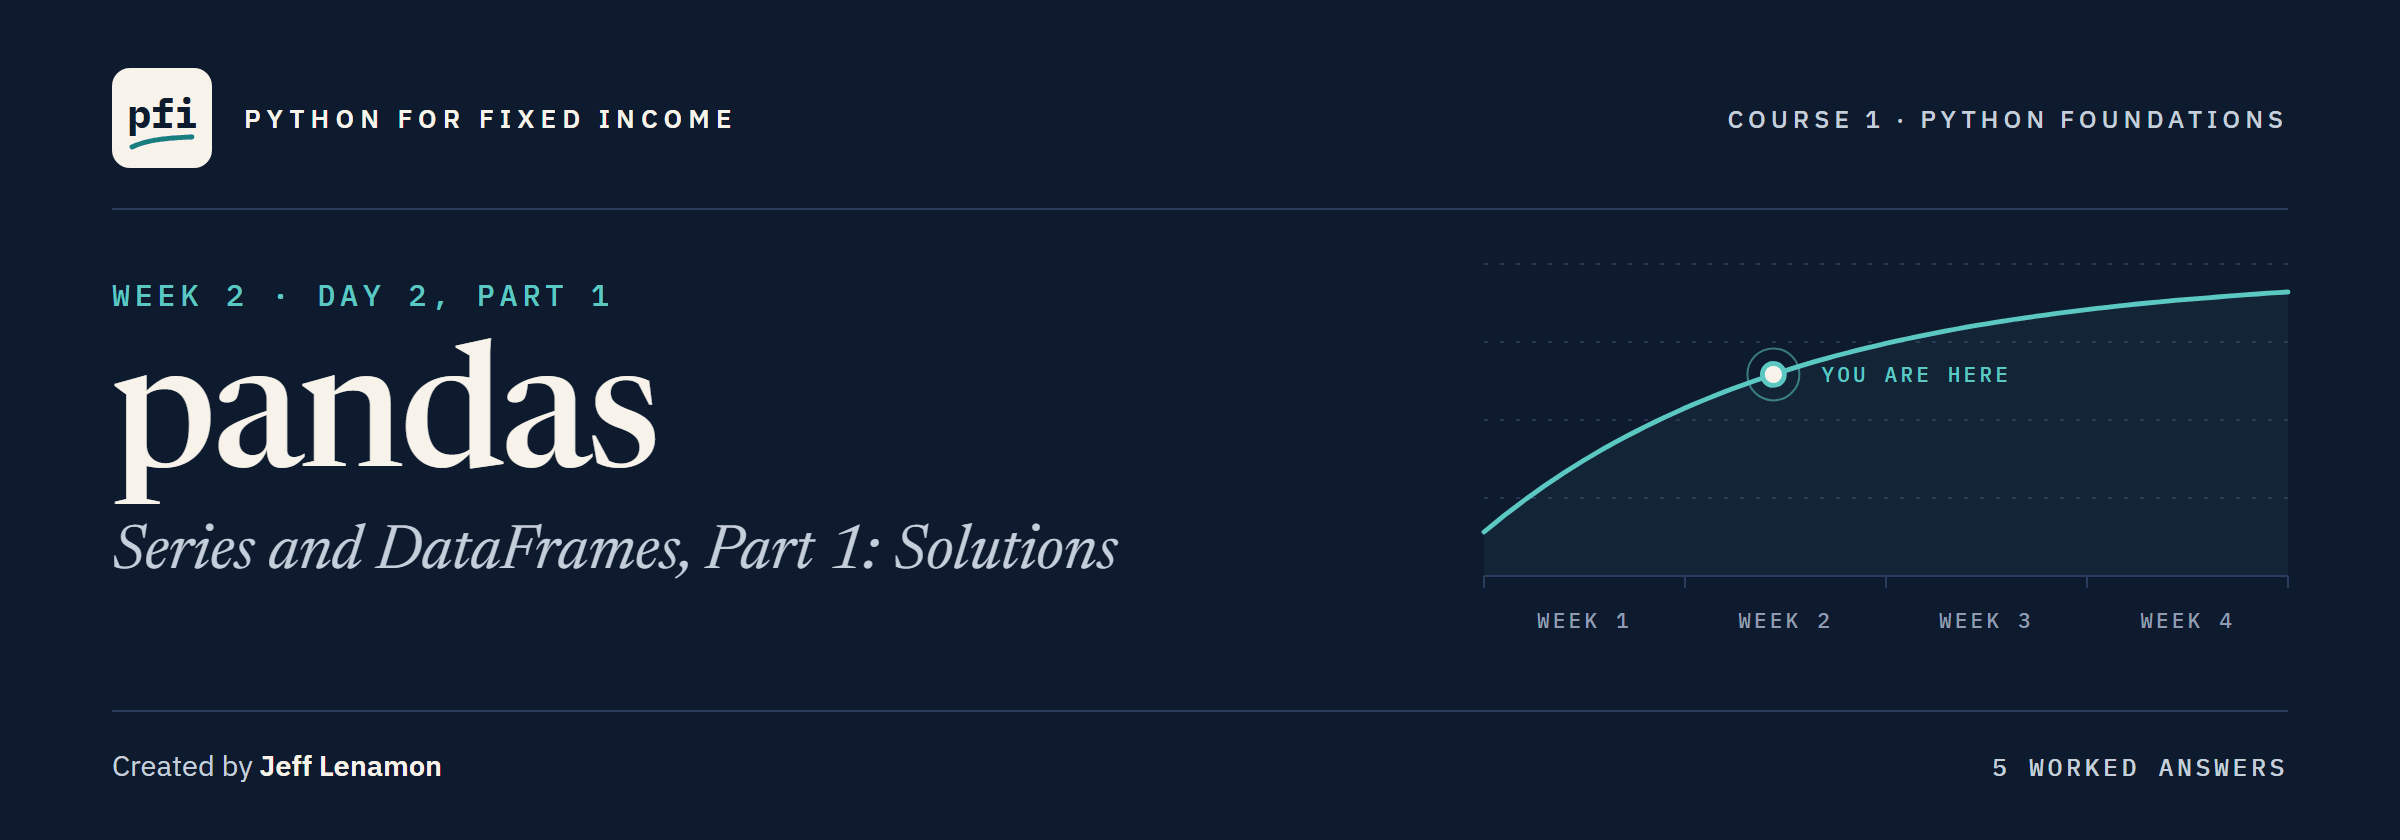

# pandas: Series and DataFrames, Part 1: Solutions

Week 2, Day 2, Part 1. Worked answers to the exercises. Try each one yourself first.

> This course is educational content created in a personal capacity. Nothing here is investment advice or a recommendation to buy or sell any security. All portfolio data is synthetic.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course01_python_foundations/week2/day2/07_pandas_series_and_dataframes_solutions.ipynb)

## Exercises

These are the worked answers to the exercises in the teaching notebook.

They use the second desk's three bonds and the 200-bond holdings file; the issuers are invented.

<table align="left">
<tr><th align="left">Ticker</th><th align="left">Coupon (%)</th><th align="left">Price</th><th align="left">Face held</th></tr>
<tr><td align="left">TRNW</td><td align="left">4.375</td><td align="left">96.25</td><td align="left">2,000,000</td></tr>
<tr><td align="left">OSMC</td><td align="left">5.00</td><td align="left">100.00</td><td align="left">1,250,000</td></tr>
<tr><td align="left">CLDB</td><td align="left">8.25</td><td align="left">104.50</td><td align="left">500,000</td></tr>
</table>
<br clear="left">

Each answer is followed by the check cell from the teaching notebook.
Run the next cell first: it imports pandas, loads a fresh copy of the holdings, and defines `check`.

In [1]:
import os

import pandas as pd


def check(label, answer, expected):
    """Compare an exercise answer to the expected value and print the result."""
    if answer is ... or answer is None:
        print(label + ': not attempted yet')
        return
    # getattr(answer, 'ndim', 0) reads answer's ndim, its number of dimensions, as in NumPy
    # Part 1, and gives 0 when answer has none: a single number or a piece of text;
    # isinstance(expected, list) is True when expected is a list
    if getattr(answer, 'ndim', 0) > 0 and not isinstance(expected, list):
        # a whole column or table was stored where a single value is expected
        print(label + ': not yet. A single value is expected, and you have a column or a table.')
        return
    if isinstance(expected, list):
        # a list of values: the same values in the same order
        correct = list(answer) == expected
    elif isinstance(expected, float):
        # single numbers with a decimal point: within a small tolerance;
        # abs() drops the sign, so this is the size of the gap between the two
        correct = abs(answer - expected) < 0.000001
    else:
        correct = answer == expected
    if correct:
        print(label + ': correct')
    else:
        print(label + ': not yet. You have', answer)


# a fresh copy of the holdings. In Colab it is read from GitHub.
if os.path.exists('../../../data/holdings.csv'):
    data_path = '../../../data/holdings.csv'
else:
    data_path = 'https://raw.githubusercontent.com/lenamonj/python-fixed-income/main/data/holdings.csv'

holdings = pd.read_csv(data_path)
print(holdings.shape)

(200, 19)


### Exercise 1

Q. Put the prices, the coupons, and the face amounts of the second desk in three Series, each labelled with the tickers. Look up the price of OSMC by its label and store it in **ex1_osmc_price**. Look up the last price by its position and store it in **ex1_last_price**. Then find the total annual coupon income and store it in **ex1_income**.

In [2]:
second_tickers = ['TRNW', 'OSMC', 'CLDB']

# one Series per column, each with the tickers as its labels
second_prices = pd.Series([96.25, 100.0, 104.5], index=second_tickers)
second_coupons = pd.Series([4.375, 5.0, 8.25], index=second_tickers)
second_faces = pd.Series([2000000, 1250000, 500000], index=second_tickers)

# a label in square brackets looks up by label, and iloc looks up by position
ex1_osmc_price = second_prices['OSMC']
ex1_last_price = second_prices.iloc[-1]

# the coupon is in percent of face
ex1_income = (second_faces * second_coupons / 100).sum()

print('OSMC:', ex1_osmc_price)
print('Last price:', ex1_last_price)
print('Total annual coupon income:', ex1_income)

OSMC: 100.0
Last price: 104.5
Total annual coupon income: 191250.0


100 for OSMC, 104.5 for the last bond, CLDB, and 191,250 of coupon a year.

In [3]:
check('Exercise 1 OSMC price', ex1_osmc_price, 100.0)
check('Exercise 1 last price', ex1_last_price, 104.5)
check('Exercise 1 income', ex1_income, 191250.0)

Exercise 1 OSMC price: correct
Exercise 1 last price: correct
Exercise 1 income: correct


### Exercise 2

Q. Put the second desk in a DataFrame named **ex2_desk**, with the columns `Ticker`, `Coupon`, `Price`, and `Face`. Store its number of rows in **ex2_rows** and its number of columns in **ex2_columns**. Then pull out the `Price` column and store its average in **ex2_avg_price**.

In [4]:
# each key is a column name and each list is a column
ex2_desk = pd.DataFrame({
    'Ticker': ['TRNW', 'OSMC', 'CLDB'],
    'Coupon': [4.375, 5.0, 8.25],
    'Price': [96.25, 100.0, 104.5],
    'Face': [2000000, 1250000, 500000],
})

# shape is (rows, columns)
ex2_rows = ex2_desk.shape[0]
ex2_columns = ex2_desk.shape[1]

# one column is a Series, so mean() works on it
ex2_avg_price = ex2_desk['Price'].mean()

print(ex2_desk)
print('Rows and columns:', ex2_rows, ex2_columns)
print('Average price:', ex2_avg_price)

  Ticker  Coupon   Price     Face
0   TRNW   4.375   96.25  2000000
1   OSMC   5.000  100.00  1250000
2   CLDB   8.250  104.50   500000
Rows and columns: 3 4
Average price: 100.25


Three rows and four columns, and an average price of 100.25.

In [5]:
check('Exercise 2 rows', ex2_rows, 3)
check('Exercise 2 columns', ex2_columns, 4)
check('Exercise 2 average price', ex2_avg_price, 100.25)

Exercise 2 rows: correct
Exercise 2 columns: correct
Exercise 2 average price: correct


### Exercise 3

Q. From the holdings, keep only the `ticker`, `sector`, `rating`, and `oas` columns, in a table named **ex3_table**. Store its number of columns in **ex3_columns**. Then find the highest yield in the file and the lowest coupon, and store them in **ex3_max_yield** and **ex3_min_coupon**.

In [6]:
# a list of column names inside the square brackets returns a smaller table
ex3_table = holdings[['ticker', 'sector', 'rating', 'oas']]
ex3_columns = ex3_table.shape[1]

# one column name returns a Series, and max() and min() work on it
ex3_max_yield = holdings['yield_pct'].max()
ex3_min_coupon = holdings['coupon'].min()

print('Columns:', ex3_columns)
print('Highest yield:', ex3_max_yield)
print('Lowest coupon:', ex3_min_coupon)

Columns: 4
Highest yield: 19.304
Lowest coupon: 3.25


Four columns; the highest yield in the file is 19.304 percent and the lowest coupon 3.25 percent.

In [7]:
check('Exercise 3 columns', ex3_columns, 4)
check('Exercise 3 highest yield', ex3_max_yield, 19.304)
check('Exercise 3 lowest coupon', ex3_min_coupon, 3.25)

Exercise 3 columns: correct
Exercise 3 highest yield: correct
Exercise 3 lowest coupon: correct


### Exercise 4

Q. Make a table indexed by CUSIP and use `loc` to look up the price and the rating of the bond with CUSIP 99071TAG7. Store them in **ex4_price** and **ex4_rating**. Then use `iloc` on the holdings to find the ticker of the last bond in the file, and store it in **ex4_last_ticker**.

In [8]:
# the CUSIP as the row label
by_cusip = holdings.set_index('cusip')

# loc[row label, column name] returns a single value
ex4_price = by_cusip.loc['99071TAG7', 'price']
ex4_rating = by_cusip.loc['99071TAG7', 'rating']

# position -1 is the last row, and column 2 is the ticker
ex4_last_ticker = holdings.iloc[-1, 2]

print('Price:', ex4_price)
print('Rating:', ex4_rating)
print('Last ticker:', ex4_last_ticker)

Price: 97.612
Rating: A-
Last ticker: ZEPN


The bond is a CORL priced at 97.612 and rated A-; the last bond in the file is a ZEPN.

In [9]:
check('Exercise 4 price', ex4_price, 97.612)
check('Exercise 4 rating', ex4_rating, 'A-')
check('Exercise 4 last ticker', ex4_last_ticker, 'ZEPN')

Exercise 4 price: correct
Exercise 4 rating: correct
Exercise 4 last ticker: correct


### Exercise 5: AI check

The second desk's face amounts arrive from another system, listed from the smallest position to the largest.

You ask an AI assistant for the total annual coupon income; it has one bug.

Q. Read the code before you run it. What number do you expect? You worked out the income yourself in Exercise 1. Then run the code. Does it agree with you?

The answer from Exercise 1 is 191,250; the original code printed 249,375, with no error.

The bug was `.to_numpy()`: it takes the labels off the face amounts, so the faces met the coupons by position.

CLDB's 500,000 met TRNW's 4.375 and TRNW's 2,000,000 met CLDB's 8.25; OSMC sat in the middle of both lists and was right by luck.

Without `.to_numpy()`, pandas matches the two Series by ticker, and the order the faces arrived in does not matter.
The result looked like an income, so nothing stood out; the check that caught it was a number worked out independently.

In [10]:
ai_coupons = pd.Series([4.375, 5.0, 8.25], index=['TRNW', 'OSMC', 'CLDB'])
ai_faces = pd.Series([500000, 1250000, 2000000], index=['CLDB', 'OSMC', 'TRNW'])

# two Series, so pandas lines the rows up by ticker before it multiplies
ex5_income = (ai_faces * ai_coupons / 100).sum()
print(f'Total annual coupon income: {ex5_income:,.0f}')

Total annual coupon income: 191,250


In [11]:
check('Exercise 5 income', ex5_income, 191250.0)

Exercise 5 income: correct


[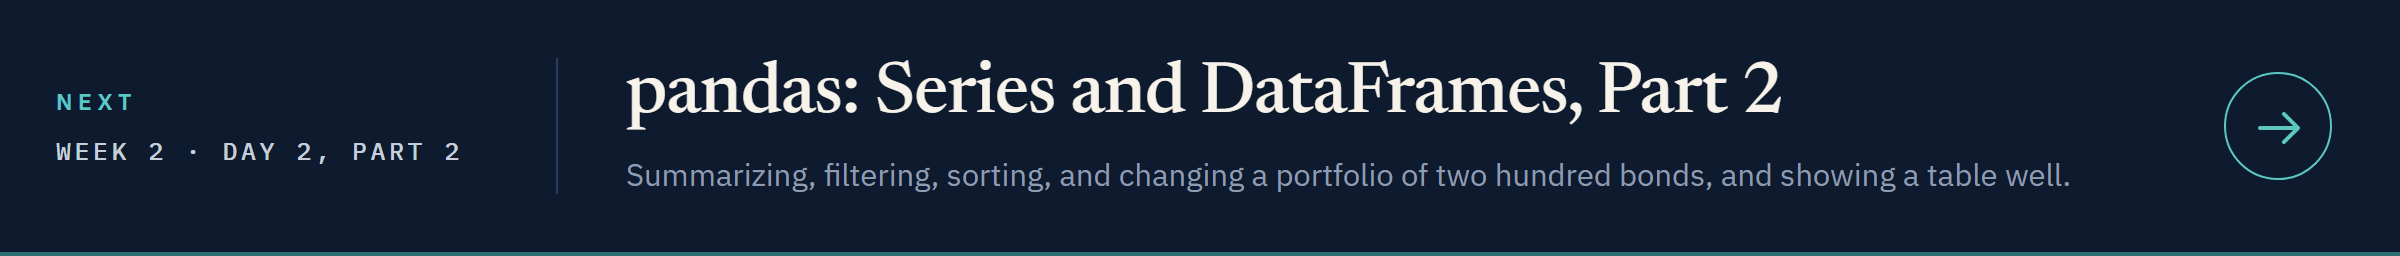](../day2_part2/07_part2_pandas_series_and_dataframes.ipynb)

[Open Day 2, Part 2 in Colab](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course01_python_foundations/week2/day2_part2/07_part2_pandas_series_and_dataframes.ipynb)